# Pac-Man com Aprendizagem por Reforço (Q-learning)

O Pac-Man (agente) começa em **S**, precisa chegar à cereja **E**  e morre se encostar num fantasma **T**. Ele não recebe o mapa pronto: aprende por tentativa e erro.


In [1]:
import numpy as np
import random
from collections import deque
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle, Rectangle, Wedge
from IPython.display import HTML, display

## Labirinto
- `S` entrada 
- `E` saída 
- `#` parede 
- `T` armadilha (o walker morre) 
- `.` caminho livre (com bolinha)

In [2]:
MAZE = [list(row) for row in [
    "S..#....#...T...",
    ".#.#.T#.#.#.###.",
    ".#...#..#.#...#.",
    ".T##.#.##.###.#.",
    "...#.#.T..#...#.",
    "#T.#T#.####.###.",
    "...T...#....#...",
    ".#T..#.#.##.#.#.",
    ".#.###.#.#T.#.#.",
    ".#.....#.#..#.#.",
    ".####T.#.####.#.",
    ".....T..........",
    ".######.######T.",
    ".#...T..#.....#.",
    ".#.#####.#.##.#.",
    "...T....T#...#.E",
]]

N_ROWS, N_COLS = len(MAZE), len(MAZE[0])
N_GHOSTS = sum(row.count("T") for row in MAZE)
ACTIONS = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}
ACTION_NAME = {0: "↑", 1: "↓", 2: "←", 3: "→"}

def find(char):
    for i, row in enumerate(MAZE):
        if char in row:
            return (i, row.index(char))

START, EXIT = find("S"), find("E")

##  Ambiente
Dado um estado e uma ação, `step` devolve o novo estado, a recompensa e se o episódio acabou.
- Passo normal: `-1` (incentiva o caminho mais curto).
- Bateu na borda ou na parede: fica no lugar e leva uma punição pequena.
- Bolinha comida pela 1ª vez no episódio: `PELLET_BONUS` compensa o custo do passo.

In [3]:
PELLET_BONUS = 3


def step(state, action, eaten=None):
    di, dj = ACTIONS[action]
    i, j = state[0] + di, state[1] + dj
    if not (0 <= i < N_ROWS and 0 <= j < N_COLS) or MAZE[i][j] == "#":
        return state, -5, False, "wall"
    cell = MAZE[i][j]
    if cell == "T":
        return (i, j), -100, True, "died"
    if cell == "E":
        return (i, j), +100, True, "exit"
    if eaten is not None and cell == "." and (i, j) not in eaten:
        eaten.add((i, j))
        return (i, j), -1 + PELLET_BONUS, False, "ate"
    return (i, j), -1, False, "moved"      


def draw(path=None, position=None):
    path = set(path or [])
    for i in range(N_ROWS):
        row = ""
        for j in range(N_COLS):
            c = MAZE[i][j]
            if (i, j) == position:
                c = "W"
            elif (i, j) in path and c == ".":
                c = "*"
            row += c + " "
        print(row)
    print()

### Fantasmas aleatórios
Ao fim de cada fase (bloco de `PHASE` episódios), se o walker treinado consegue sair vivo, os fantasmas `T` vão para células que **não** tinham fantasma e ele precisa achar o caminho de novo (a Q-table é mantida, mas esquecemos o medo das células onde havia fantasma). O sorteio se repete até existir um caminho livre de `S` até `E`. Na última fase não trocamos, para o teste final ser justo.

In [4]:
def solvable():
    seen, q = {START}, deque([START])
    while q:
        i, j = q.popleft()
        if (i, j) == EXIT:
            return True
        for di, dj in ACTIONS.values():
            n = (i + di, j + dj)
            if 0 <= n[0] < N_ROWS and 0 <= n[1] < N_COLS and n not in seen and MAZE[n[0]][n[1]] not in "#T":
                seen.add(n); q.append(n)
    return False


def move_ghosts(rng):
    old = {(i, j) for i in range(N_ROWS) for j in range(N_COLS) if MAZE[i][j] == "T"}
    for i, j in old:
        MAZE[i][j] = "."
    free = [(i, j) for i in range(N_ROWS) for j in range(N_COLS) if MAZE[i][j] == "." and (i, j) not in old]
    while True:
        new = rng.sample(free, N_GHOSTS)
        for i, j in new:
            MAZE[i][j] = "T"
        if solvable():
            return old
        for i, j in new:
            MAZE[i][j] = "."

##  Parâmetros do Q-learning
- `alpha` — taxa de aprendizado
- `gamma` — peso do futuro
- `epsilon` — exploração inicial (100% aleatório)
- `epsilon_min` — exploração mínima no fim do treino
- `decay` — quanto o epsilon diminui a cada episódio
- `N_EPISODES` — quantas tentativas o Pac-Man faz
- `MAX_STEPS` — limite de passos por tentativa

In [5]:
alpha = 0.2          
gamma = 0.5          
epsilon = 1.0       
epsilon_min = 0.001  
decay = 0.998       
N_EPISODES = 3000   
MAX_STEPS = 400     
PHASE = 100         
SEED = 42

## Treinamento
`train` roda o Q-learning, imprime um resumo a cada fase e guarda o último caminho de cada fase (usado no vídeo).
`run_greedy` faz o walker andar sozinho, sem exploração.

In [6]:
def run_greedy(Q):
    state, path, actions, eaten = START, [START], [], set()
    for _ in range(MAX_STEPS):
        action = int(np.argmax(Q[state]))
        state, _, done, event = step(state, action, eaten)
        path.append(state); actions.append(action)
        if done:
            return path, event, actions
    return path, "lost", actions


def train(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    ghost_rng = random.Random(seed)
    Q = np.zeros((N_ROWS, N_COLS, 4))   
    eps = epsilon
    history, rewards, recorded, recorded_mazes = [], [], [], []   

    for episode in range(1, N_EPISODES + 1):
        state, total, path, result = START, 0, [START], "lost"
        eaten = set()  

        for _ in range(MAX_STEPS):
            if random.random() < eps:
                action = random.randint(0, 3)
            else:
                action = int(np.argmax(Q[state]))

            new_state, r, done, event = step(state, action, eaten)
            target = r if done else r + gamma * np.max(Q[new_state])
            Q[state][action] += alpha * (target - Q[state][action])

            state, total = new_state, total + r
            path.append(state)
            if done:
                result = event
                break

        eps = max(epsilon_min, eps * decay)
        history.append(result)
        rewards.append(total)

        if episode % PHASE == 0:
            last = history[-PHASE:]
            title = (f"Fase {episode // PHASE}  (ep. {episode})  |  sucessos {last.count('exit')}/{PHASE}"
                     f"  |  mortes {last.count('died')}/{PHASE}")
            recorded.append((title, path, result))
            recorded_mazes.append([row[:] for row in MAZE])
            print(f"{title}  |  epsilon={eps:.3f}  |  último: {result.upper()} em {len(path) - 1} passos")
            if episode < N_EPISODES and run_greedy(Q)[1] == "exit":
                for gi, gj in move_ghosts(ghost_rng):
                    for a, (di, dj) in ACTIONS.items():
                        if 0 <= gi - di < N_ROWS and 0 <= gj - dj < N_COLS:
                            Q[gi - di, gj - dj, a] = 0
                print("   -> passou! fantasmas mudaram de lugar, ele precisa achar o caminho de novo")

    path, result, _ = run_greedy(Q)
    recorded.append(("TESTE FINAL: walker treinado", path, result))
    recorded_mazes.append([row[:] for row in MAZE])
    return Q, history, rewards, recorded, recorded_mazes


Q, history, rewards, recorded_episodes, recorded_mazes = train()

first = history.index("exit") + 1 if "exit" in history else None
print(f"\nPrimeiro sucesso no episódio: {first}" + (f"  (fase {-(-first // PHASE)})" if first else ""))

Fase 1  (ep. 100)  |  sucessos 0/100  |  mortes 100/100  |  epsilon=0.819  |  último: DIED em 23 passos
Fase 2  (ep. 200)  |  sucessos 0/100  |  mortes 100/100  |  epsilon=0.670  |  último: DIED em 7 passos
Fase 3  (ep. 300)  |  sucessos 0/100  |  mortes 100/100  |  epsilon=0.548  |  último: DIED em 10 passos
Fase 4  (ep. 400)  |  sucessos 0/100  |  mortes 100/100  |  epsilon=0.449  |  último: DIED em 7 passos
Fase 5  (ep. 500)  |  sucessos 0/100  |  mortes 100/100  |  epsilon=0.368  |  último: DIED em 39 passos
Fase 6  (ep. 600)  |  sucessos 1/100  |  mortes 95/100  |  epsilon=0.301  |  último: DIED em 30 passos
Fase 7  (ep. 700)  |  sucessos 0/100  |  mortes 98/100  |  epsilon=0.246  |  último: DIED em 127 passos
Fase 8  (ep. 800)  |  sucessos 1/100  |  mortes 96/100  |  epsilon=0.202  |  último: DIED em 29 passos
Fase 9  (ep. 900)  |  sucessos 38/100  |  mortes 59/100  |  epsilon=0.165  |  último: DIED em 15 passos
Fase 10  (ep. 1000)  |  sucessos 74/100  |  mortes 26/100  |  epsilo

### Teste final
O agente treinado anda sozinho, sem exploração.

In [ ]:
path, event, actions = run_greedy(Q)
print("Walker treinado percorrendo o labirinto:\n")
for n, (a, pos) in enumerate(zip(actions, path[1:]), 1):
    print(f"Passo {n:2d}: {ACTION_NAME[a]} -> {pos}")

print()
draw(path, position=path[-1])
if event == "exit":
    print(f"SUCESSO! O agente saiu vivo do labirinto em {len(path) - 1} passos.")
else:
    print(f"Não conseguiu sair (resultado: {event}). Tente aumentar N_EPISODES.")

Walker treinado percorrendo o labirinto:

Passo  1: ↓ -> (1, 0)
Passo  2: ↓ -> (2, 0)
Passo  3: ↓ -> (3, 0)
Passo  4: ↓ -> (4, 0)
Passo  5: → -> (4, 1)
Passo  6: ↓ -> (5, 1)
Passo  7: ↓ -> (6, 1)
Passo  8: → -> (6, 2)
Passo  9: ↓ -> (7, 2)
Passo 10: ↓ -> (8, 2)
Passo 11: ↓ -> (9, 2)
Passo 12: → -> (9, 3)
Passo 13: → -> (9, 4)
Passo 14: → -> (9, 5)
Passo 15: → -> (9, 6)
Passo 16: ↑ -> (8, 6)
Passo 17: ↑ -> (7, 6)
Passo 18: ↑ -> (6, 6)
Passo 19: ↑ -> (5, 6)
Passo 20: ↑ -> (4, 6)
Passo 21: → -> (4, 7)
Passo 22: → -> (4, 8)
Passo 23: → -> (4, 9)
Passo 24: ↑ -> (3, 9)
Passo 25: ↑ -> (2, 9)
Passo 26: ↑ -> (1, 9)
Passo 27: ↑ -> (0, 9)
Passo 28: → -> (0, 10)
Passo 29: → -> (0, 11)
Passo 30: → -> (0, 12)
Passo 31: → -> (0, 13)
Passo 32: → -> (0, 14)
Passo 33: → -> (0, 15)
Passo 34: ↓ -> (1, 15)
Passo 35: ↓ -> (2, 15)
Passo 36: ↓ -> (3, 15)
Passo 37: ↓ -> (4, 15)
Passo 38: ↓ -> (5, 15)
Passo 39: ↓ -> (6, 15)
Passo 40: ↓ -> (7, 15)
Passo 41: ↓ -> (8, 15)
Passo 42: ↓ -> (9, 15)
Passo 43: ↓ -> (10,

###  Mapa 2D do cenário

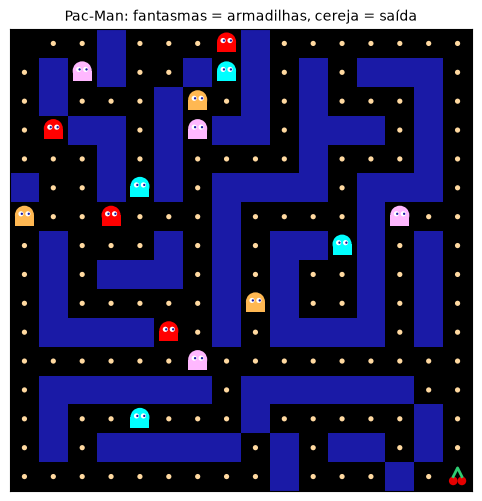

In [10]:
CODE = {".": 0, "#": 1, "T": 0, "S": 0, "E": 0}
COLORS = ListedColormap(["#000000", "#1a1aa6"])
GRID = np.array([[CODE[c] for c in row] for row in MAZE])
GHOST_COLORS = ["#ff0000", "#ffb8ff", "#00ffff", "#ffb852"]   


def draw_ghost(ax, x, y, col):
    parts = [ax.add_patch(Circle((x, y - .05), .33, fc=col, ec="none", zorder=3)),
             ax.add_patch(Rectangle((x - .33, y - .05), .66, .36, fc=col, ec="none", zorder=3))]
    for dx in (-.12, .12):
        parts.append(ax.add_patch(Circle((x + dx, y - .1), .09, fc="white", ec="none", zorder=4)))
        parts.append(ax.add_patch(Circle((x + dx + .03, y - .1), .04, fc="#1a1aa6", ec="none", zorder=4)))
    return parts


def draw_base(ax, dynamic=True):   
    ax.set_facecolor("black")
    ax.imshow(GRID, cmap=COLORS, vmin=0, vmax=1)
    k, pellets = 0, {}
    for i in range(N_ROWS):
        for j in range(N_COLS):
            c = MAZE[i][j]
            if c == "." and dynamic:
                pellets[(i, j)] = Circle((j, i), .09, fc="#ffd9a0", ec="none", zorder=2)
                ax.add_patch(pellets[(i, j)])
            elif c == "T" and dynamic:
                draw_ghost(ax, j, i, GHOST_COLORS[k % 4]); k += 1
            elif c == "E":
                for dx in (-.15, .15):
                    ax.add_patch(Circle((j + dx, i + .15), .15, fc="#e60000", ec="none", zorder=3))
                ax.plot([j - .15, j, j + .15], [i, i - .3, i], color="#2ecc71", lw=2, zorder=3)
    ax.set_xticks([]); ax.set_yticks([])
    return pellets


def plot_maze(path=None, title="Labirinto"):
    fig, ax = plt.subplots(figsize=(6, 6))
    draw_base(ax)
    if path:
        ys, xs = zip(*path)
        ax.plot(xs, ys, "-o", color="#f39c12", lw=2, ms=4)
    ax.set_title(title, fontsize=10)
    plt.show()


plot_maze(title="Pac-Man: fantasmas = armadilhas, cereja = saída")

### Geração de vídeo
O Pac-Man anda em cada fase até aprender.

In [12]:
def make_video(recorded, mazes, max_steps_per_phase=60, pause=8, fps=6, filename="walker_labirinto"):
    frame_list = []
    for k, (_, path, _) in enumerate(recorded):
        n = min(len(path), max_steps_per_phase)
        frame_list += [(k, p) for p in range(n)]

    fig, ax = plt.subplots(figsize=(6.5, 7))
    draw_base(ax, dynamic=False)
    pellets = {(i, j): ax.add_patch(Circle((j, i), .09, fc="#ffd9a0", ec="none", zorder=2))
               for i in range(N_ROWS) for j in range(N_COLS) if any(m[i][j] == "." for m in mazes)}
    ghosts = [[draw_ghost(ax, j, i, GHOST_COLORS[g % 4])
               for g, (i, j) in enumerate((i, j) for i in range(N_ROWS) for j in range(N_COLS) if m[i][j] == "T")]
              for m in mazes]   
    trail, = ax.plot([], [], "-", color="#f39c12", lw=2, alpha=.6)
    walker = Wedge((0, 0), .4, 30, 330, fc="#f1c40f", ec="black", lw=1.5, zorder=5)
    ax.add_patch(walker)
    title = ax.set_title("", fontsize=10)
    banner = ax.text(N_COLS / 2 - .5, N_ROWS / 2 - .5, "", ha="center", va="center",
                    fontsize=34, weight="bold")

    angle = [0]  

    def update(q):
        k, p = frame_list[q]
        name, path, result = recorded[k]
        ys, xs = zip(*path[:p + 1])
        trail.set_data(xs, ys)
        visited = set(path[:p + 1])
        for pos, b in pellets.items():
            b.set_visible(mazes[k][pos[0]][pos[1]] == "." and pos not in visited)
        for g, parts in enumerate(ghosts):
            for grp in parts:
                for a in grp:
                    a.set_visible(g == k)
        if p > 0 and (xs[-1], ys[-1]) != (xs[-2], ys[-2]):
            angle[0] = np.degrees(np.arctan2(ys[-1] - ys[-2], xs[-1] - xs[-2]))
        mouth = 35 if p % 2 == 0 else 5
        walker.set_center((xs[-1], ys[-1]))
        walker.set_theta1(angle[0] + mouth); walker.set_theta2(angle[0] + 360 - mouth)
        title.set_text(f"{name}\npasso {p}")
        is_last = p == min(len(path), max_steps_per_phase) - 1
        if is_last and result == "exit":
            banner.set_text("SAIU VIVO!"); banner.set_color("#27ae60")
        elif is_last and result == "died":
            banner.set_text("MORREU!"); banner.set_color("#c0392b")
        elif is_last:
            banner.set_text("PERDIDO"); banner.set_color("#7f8c8d")
        else:
            banner.set_text("")
        return trail, walker, title, banner

    anim = animation.FuncAnimation(fig, update, frames=len(frame_list), interval=1000 / fps, blit=False)
    plt.close(fig)

    return anim


anim = make_video(recorded_episodes, recorded_mazes)
HTML(anim.to_jshtml())       

Animation size has reached 21015006 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


### Caminho final aprendido

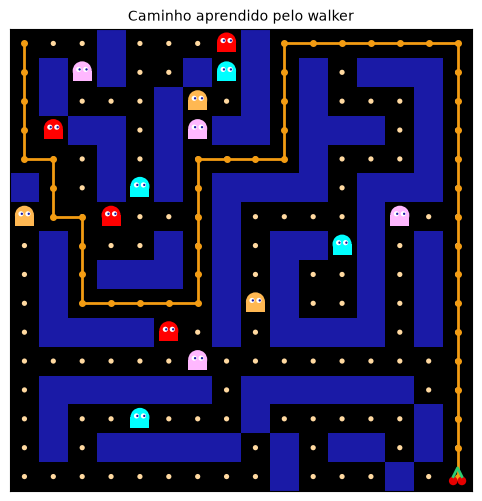

In [ ]:
plot_maze(recorded_episodes[-1][1], title="Caminho aprendido pelo agente")